# Assignment 2: preliminary results

This notebook rebuilds every table and the figure in our Assignment 2 report from the saved result files. It does not rerun experiments. Each number comes from `results/<experiment>/metrics.csv`, written by the scripts below.

| Result | Script that produced it |
|---|---|
| MICA reproduction on the authors' inputs | `scripts/run_mica_job.sh`, `scripts/mica_seeded_kmeans.py`, `scripts/score_mica.py` |
| Leiden, k-means and hierarchical baselines | `scripts/run_baselines.py` |
| Label-free choice (defaults, silhouette) | `scripts/run_label_free.py`, `scripts/mica_label_free.py` |
| Neighbor search on PBMC14K and Allen 100K | `scripts/run_rq2_large.py`, `scripts/run_rq2_allen.py` |
| MICA's later steps on each graph | `scripts/mica_downstream.py`, `scripts/score_downstream.py` |

The data live outside git (see `README.md`). The environment is `envs/scminer.yml`.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from scminer_clust.paths import REPO, RESULTS
sys.path.insert(0, str(REPO / "scripts"))
import a2_report
a2_report.main()   # writes latex/tables/a2_*.tex, latex/figures/a2_neighbor_recall.pdf and results/a2_report_numbers.json
nums = json.loads((RESULTS / "a2_report_numbers.json").read_text())

{
 "default": {
  "pbmc14k": {
   "mica": {
    "median": 0.8443105265117983,
    "min": 0.8367332743881749,
    "max": 0.8508557563983226,
    "n": 6,
    "values": [
     0.8463,
     0.8367,
     0.838,
     0.8509,
     0.8424,
     0.8467
    ]
   },
   "mica_ami": {
    "median": 0.8676527678811676,
    "min": 0.8628921671061861,
    "max": 0.8709798649038318,
    "n": 6,
    "values": [
     0.868,
     0.8657,
     0.8629,
     0.871,
     0.8673,
     0.8707
    ]
   },
   "mica_k": "7",
   "leiden": {
    "median": 0.8659883490592166,
    "min": 0.8532559866723938,
    "max": 0.8671499837573449,
    "n": 3,
    "values": [
     0.8533,
     0.866,
     0.8671
    ]
   },
   "leiden_ami": {
    "median": 0.8925886691275131,
    "min": 0.8855668529864086,
    "max": 0.8926057268992824,
    "n": 3,
    "values": [
     0.8856,
     0.8926,
     0.8926
    ]
   },
   "leiden_k": "8"
  },
  "zeisel": {
   "mica": {
    "median": 0.608420245516162,
    "min": 0.5380363384981263,
  

## Table I. Reproduction on the authors' inputs (ARI, the paper's rule)

In [2]:
t1 = pd.DataFrame({ds: {"cells": r["cells"], "MICA, paper": r["published_mica"], "MICA, ours": round(r["ours_mica"]["median"], 3),
                         "Scanpy, paper": r["published_scanpy"], "Leiden all genes, ours": round(r["ours_leiden_all_genes"]["median"], 3)}
                    for ds, r in nums["reproduction"].items()}).T
t1["within 0.05"] = (t1["MICA, ours"] - t1["MICA, paper"]).abs() <= 0.05
t1

,cells,"MICA, paper","MICA, ours","Scanpy, paper","Leiden all genes, ours",within 0.05
yan,124.0,0.939,0.939,0.839,0.789,True
goolam,124.0,0.544,0.544,0.572,0.308,True
buettner,182.0,0.934,0.934,0.277,0.268,True
pollen,249.0,0.942,0.951,0.874,0.858,True
chung,317.0,0.655,0.655,0.170,0.319,True
usoskin,622.0,0.847,0.835,0.860,0.598,True
kolodziejczyk,704.0,1.000,0.727,0.996,0.564,False
klein,2717.0,0.980,0.980,0.820,0.977,True
zeisel,2903.0,0.744,0.764,0.630,0.839,True
pbmc14k,13605.0,0.853,0.854,0.754,0.878,True


## Table II. Choosing the clustering without and with labels (PBMC14K and Zeisel, all genes)

Median [min, max] ARI over six MICA graph-mode runs or three Leiden seeds, and the number of clusters chosen.

In [3]:
rows = []
for rule, name in [("default", "No labels: default"), ("silhouette", "No labels: silhouette"), ("paper", "Labels pick: paper's rule")]:
    for meth in ["mica", "leiden"]:
        r = {"rule": name, "method": meth}
        for ds in ["pbmc14k", "zeisel"]:
            s = nums["selection"][rule][ds]
            r[f"{ds} ARI"] = f"{s[meth]['median']:.3f} [{s[meth]['min']:.3f}, {s[meth]['max']:.3f}]"
            r[f"{ds} AMI"] = round(s[meth + '_ami']["median"], 3)
            r[f"{ds} k"] = s[meth + "_k"]
        rows.append(r)
pd.DataFrame(rows)

,rule,method,pbmc14k ARI,pbmc14k AMI,pbmc14k k,zeisel ARI,zeisel AMI,zeisel k
0,No labels: default,mica,"0.844 [0.837, 0.851]",0.868,7,"0.608 [0.538, 0.717]",0.704,9 to 11
1,No labels: default,leiden,"0.866 [0.853, 0.867]",0.893,8,"0.378 [0.366, 0.381]",0.644,21
2,No labels: silhouette,mica,"0.624 [0.616, 0.833]",0.783,5 or 7,"0.659 [0.634, 0.735]",0.731,9
3,No labels: silhouette,leiden,"0.397 [0.397, 0.397]",0.725,4,"0.370 [0.360, 0.370]",0.470,2
4,Labels pick: paper's rule,mica,"0.854 [0.850, 0.857]",0.871,7,"0.764 [0.755, 0.781]",0.746,7
5,Labels pick: paper's rule,leiden,"0.878 [0.877, 0.878]",0.901,7,"0.839 [0.839, 0.839]",0.796,7


## Figure 1. Neighbor search against brute force

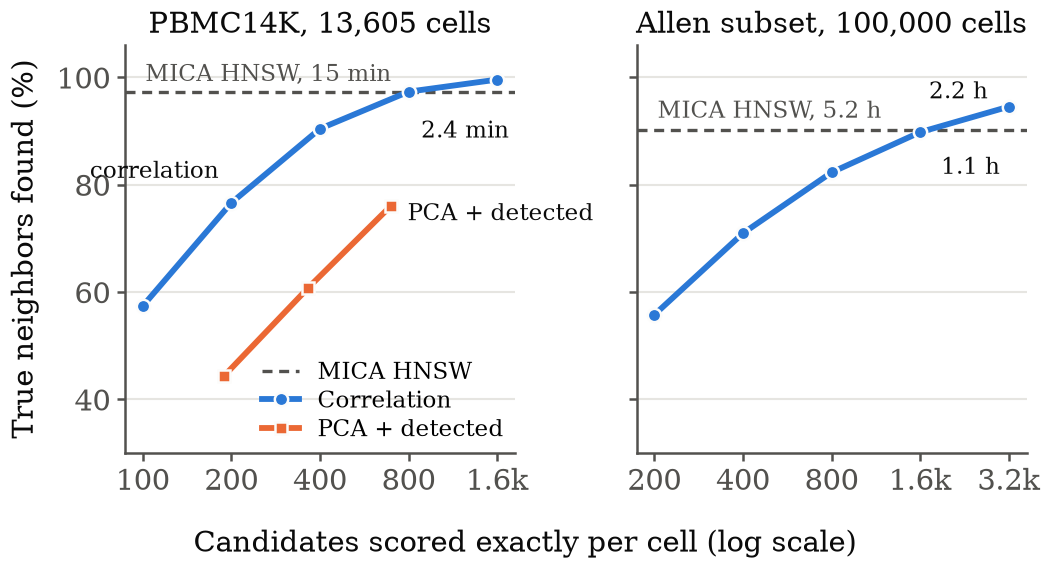

,correlation,pca_plus_detected,correlation_minutes_all_cells,hnsw_recall,hnsw_minutes,brute_force_minutes_est,correlation_hours_all_cells,hnsw_hours,brute_force_hours_est
pbmc14k,"{'100': 0.574, '200': 0.7664, '400': 0.9044, '...","{'189': 0.4435, '365': 0.6084, '696': 0.7607}","{'200': 0.5, '400': 1.0, '800': 2.4, '1600': 4.7}",0.9732,15.1,36.9,NaN,NaN,NaN
allen_100k,"{'200': 0.5578, '400': 0.7097, '800': 0.8231, ...",NaN,NaN,0.9028,NaN,NaN,"{'1600': 1.06, '3200': 2.17}",5.25,42.6


In [4]:
display(Image(filename=str(REPO / "latex" / "figures" / "a2_neighbor_recall.png"), width=700))
pd.DataFrame(nums["neighbors"]).T

## MICA's own later steps (node2vec and Louvain) on each graph

The same code runs on our fast graph and on MICA's own HNSW graph, so only the graph differs.

In [5]:
runs = []
for f in sorted(RESULTS.glob("rq2_downstream_*/metrics.csv")):
    d = pd.read_csv(f)
    runs.append({"run": f.parent.name, "dataset": d.dataset[0], "graph": d.graph[0], "ARI": round(d.ari[0], 3), "AMI": round(d.ami[0], 3), "clusters": d.n_clusters[0]})
pd.DataFrame(runs)

,run,dataset,graph,ARI,AMI,clusters
0,rq2_downstream_allen_100k_corr3200_rep1,allen_100k,corr3200,0.602,0.819,34
1,rq2_downstream_allen_100k_corr3200_rep2,allen_100k,corr3200,0.627,0.825,34
2,rq2_downstream_allen_100k_mica_hnsw_rep1,allen_100k,mica_hnsw,0.641,0.835,34
3,rq2_downstream_allen_100k_mica_hnsw_rep2,allen_100k,mica_hnsw,0.617,0.831,34
4,rq2_downstream_paper_pbmc14k_corr800_rep1,paper_pbmc14k,corr800,0.853,0.873,7
5,rq2_downstream_paper_pbmc14k_corr800_rep2,paper_pbmc14k,corr800,0.853,0.875,7
6,rq2_downstream_paper_pbmc14k_mica_hnsw_rep1,paper_pbmc14k,mica_hnsw,0.852,0.870,7
7,rq2_downstream_paper_pbmc14k_mica_hnsw_rep2,paper_pbmc14k,mica_hnsw,0.852,0.872,7
